## This code is for  segmenting the macular images

### Import necessary library files

In [1]:
import os
from os import environ
environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
environ['CUDA_VISIBLE_DEVICES'] = '0' #Select the GPU Card
print('Process id: ',os.getpid())


from os.path import dirname, abspath
from os import listdir
import os, os.path, time
import time as time
import timeit

from sys import argv
import sys



########### Load Keras Modules Needed ==========================================
#import gc
# import tensorflow as tf

# gc.collect()
# tf.keras.backend.clear_session()
import tensorflow as tf
import tensorflow.keras
# import tensorflow.keras.backend as K

from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, load_model, Model

from tensorflow.keras.layers import GlobalAveragePooling2D, GlobalMaxPooling2D, \
                                    concatenate, average, add, Reshape, Permute, Conv2D, \
                                    Conv2DTranspose, SeparableConv2D,PReLU, ELU, \
                                    BatchNormalization, \
                                    MaxPooling2D, ZeroPadding2D, UpSampling2D, \
                                    AveragePooling2D,Cropping2D, \
                                    Flatten, Dense, Dropout, Activation, Reshape,\
                                    SpatialDropout2D,Average


from tensorflow.keras.optimizers import RMSprop, SGD, Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping,\
                            LearningRateScheduler, Callback
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model,to_categorical,Sequence



# Load other functions ==================================================
import glob

import numpy as np
from numpy import zeros, newaxis
import h5py, pickle
from random import randint, choice, shuffle, sample
from itertools import product

from ipywidgets import interact, interactive, fixed #interact_manualten
import ipywidgets as widgets
from scipy import signal

import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import shutil


Process id:  747319


2025-08-13 09:36:48.439234: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-13 09:36:48.452328: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1755077808.467487  747319 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1755077808.472064  747319 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-08-13 09:36:48.488090: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

### testname

In [2]:
testname="unet_cce_pf_weight_1"

# collect images

In [3]:
imgpath = "./../../../../../mnt/DATA/sda1/ritu/Data/"

OCT_list = sorted(glob.glob(imgpath+'OCT/*.npy'))
label_list = sorted(glob.glob(imgpath+'Label/*.npy'))
print(len(OCT_list))
print(len(label_list))

print(OCT_list[0])
print(label_list[0])


5682
5682
./../../../../../mnt/DATA/sda1/ritu/Data/OCT/Spec_G_Aravind_101_55658.npy
./../../../../../mnt/DATA/sda1/ritu/Data/Label/Spec_G_Aravind_101_55658_label.npy


In [4]:
OCT_img = []
Label_img = []

### list of new images
for i in range(len(OCT_list)):
    img=np.load(OCT_list[i]) #read the image
    img = np.asarray(img, dtype=np.float32)
    img=(img-np.min(img))/(np.max(img)-np.min(img)) #normalize the intensities to bring between 0 and 1
    OCT_img.append(img)

    temp_name = (OCT_list[i].split('/')[-1]).split('.')[0]+'_label.npy'
    l_img=np.load(imgpath+'Label/' + temp_name)
    Label_img.append(l_img)


OCT_img = np.asarray(OCT_img)
Label_img = np.asarray(Label_img)

print("number of new images and labels: ",np.shape(OCT_img), np.shape(Label_img))

number of new images and labels:  (5682, 200, 400) (5682, 200, 400)


In [5]:
print(np.unique(Label_img[0]))

[0 1 2 3 4 5 6 7]


In [6]:
 def process_label(label_file):
        """
        This fucntion takes label files with layers marked from 1 to 8, not 0 to 7
        """
        colors = np.zeros((9,3),dtype=np.uint8)

        #### Define colors for each label
        colors[0] = [255, 255, 255]  # Background (white)
        colors[1] = [255, 0, 0]      # Class 1 (Red)
        colors[2] = [0, 255, 0]      # Class 2 (Green)
        colors[3] = [0, 0, 255]      # Class 3 (Blue)
        colors[4] = [75, 0, 130]     # Class 4 (Indigo)
        colors[5] = [255, 165, 0]    # Class 5 (Orange)
        colors[6] = [255, 255, 0]    # Class 6 (Yellow)      
        colors[7] = [238, 130, 238]  # Class 7 (Violet)

        H = np.shape(label_file)[0]
        W = np.shape(label_file)[1]

        img = np.zeros((H,W,3),dtype=np.uint8)
        for i,j in product(range(H),range(W)):
            img[i, j] = colors[label_file[i,j]-1]

        return np.asarray(img)

In [7]:
@interact(x=(0,len(OCT_img)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)
def h(x=0): #Starting number of the slider
#     print(OCT_list[x].split('/')[-1])
    f = plt.figure(figsize=(12,6))

    f.add_subplot(1,3, 1)
    plt.imshow(OCT_img[x], cmap='gray')
    plt.axis('off')  # Remove axes

    f.add_subplot(1,3, 2)
    color_label= process_label(Label_img[x]+1)
    plt.imshow(color_label)
    plt.axis('off')  # Remove axes

    f.add_subplot(1,3, 3)
    plt.imshow(OCT_img[x], cmap="gray")
    plt.imshow(color_label,alpha=0.25)
    plt.axis('off')  # Remove axes
    plt.show()
   

interactive(children=(IntSlider(value=0, description='x', max=5681), Output()), _dom_classes=('widget-interact…

# shuffle images

In [8]:
### shuffle new images
zipimgs=list(zip(OCT_img,Label_img)) #zip the labels  and image data
shuffle(zipimgs) #shuffle the data
OCT_img1,Label_img1=zip(*zipimgs)

print("number of new images and labels after resize: ",np.shape(OCT_img1), np.shape(Label_img1))

Label_img_exp = to_categorical(Label_img1)
print("number of new images and labels after exp: ",np.shape(OCT_img1), np.shape(Label_img_exp))


number of new images and labels after resize:  (5682, 200, 400) (5682, 200, 400)
number of new images and labels after exp:  (5682, 200, 400) (5682, 200, 400, 8)


In [9]:
@interact(x=(0,len(OCT_img1)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)
def h(x=0): #Starting number of the slider
#     print(OCT_list[x].split('/')[-1])
    f = plt.figure(figsize=(12,6))

    f.add_subplot(1,3, 1)
    plt.imshow(OCT_img1[x], cmap='gray')
    plt.axis('off')  # Remove axes

    f.add_subplot(1,3, 2)
    color_label= process_label(np.argmax(Label_img_exp[x], axis=2)+1)
    plt.imshow(color_label)
    plt.axis('off')  # Remove axes

    f.add_subplot(1,3, 3)
    plt.imshow(OCT_img1[x], cmap="gray")
    plt.imshow(color_label,alpha=0.2)
    plt.axis('off')  # Remove axes
    plt.show()

interactive(children=(IntSlider(value=0, description='x', max=5681), Output()), _dom_classes=('widget-interact…

# data split

In [10]:
# no_train_images=4546 # Number of training images
# no_test_images= 568 #Number of testing images
# no_val_images= 568 # Number of images in the validation set

no_train_images=300 # Number of training images
no_test_images= 100 #Number of testing images
no_val_images= 100 # Number of images in the validation set


W, H = 400,200 #dimension of each image from the cirrus device
nb_classes=8  #11 Layers

# no_train_images=800 # Number of training images
# no_test_images= 100 #Number of testing images
# no_val_images= 100 # Number of images in the validation set


# W, H = 400,200 #dimension of each image from the cirrus device
# nb_classes=8  #11 Layers

In [11]:
train_imgs  =OCT_img1[0:300]
train_labels=Label_img_exp[0:300]

val_imgs  =OCT_img1[300:400]
val_labels=Label_img_exp[300:400]

test_imgs  =OCT_img1[400:500]
test_labels=Label_img_exp[400:500]

train_images=np.expand_dims(train_imgs,axis=3)
val_images=np.expand_dims(val_imgs,axis=3)
test_images=np.expand_dims(test_imgs,axis=3)

print('\nTraining data dimension: {} for labels and {} for images'.format(np.shape(train_labels),np.shape(train_images)))
print('\nValidation data dimension: {} for labels and {} for images'.format(np.shape(val_labels),np.shape(val_images)))
print('\nTesting data dimension: {} for labels and {} for images'.format(np.shape(test_labels),np.shape(test_images)))


Training data dimension: (300, 200, 400, 8) for labels and (300, 200, 400, 1) for images

Validation data dimension: (100, 200, 400, 8) for labels and (100, 200, 400, 1) for images

Testing data dimension: (100, 200, 400, 8) for labels and (100, 200, 400, 1) for images


# Data generation function

In [12]:
 def DataGen(X, y, batch_sz,mode):
    alpha, alpha2, sigma = 10, 15, 50
    #alpha, alpha2, sigma = 0, 0, 60

    c = list(zip(X, y))
    croph, cropw = H,W

    shape = X[0].shape[:2]
    x_mesh, y_mesh = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))

    Xpatches = np.ndarray((batch_sz, croph, cropw, 1), dtype=np.float32)
    ypatches = np.ndarray((batch_sz, croph, cropw, nb_classes), dtype=np.float32)

    #create a mask for later purposes
    black_dx = 60
    black_dy = 20
    dark_mask = np.zeros((black_dx, black_dy))
    for k in range(black_dy):
        dark_mask[:,k] = (np.abs(k-black_dy//2) / (black_dy/2.))**2

    image_index = 0
    batch_index = 0
    while (mode==True):
        #if the batch is full, release the batch
        if batch_index == batch_sz:
            batch_index = 0
            yield Xpatches, ypatches

        if image_index >= len(X):
            image_index = 0

        #do the following at the start of each epoch
        if image_index == 0:
            #shuffle the data
            shuffle(c)
            X, y = zip(*c)
            #below is used once per epoch for the elastic deformation
            g_1d = signal.windows.gaussian(300, sigma)
            kernel_deform = np.outer(g_1d, g_1d)
            dx = signal.fftconvolve(np.random.rand(*shape) * 2 - 1, kernel_deform, mode='same')
            dy = signal.fftconvolve(np.random.rand(*shape) * 2 - 1, kernel_deform, mode='same')
            dx = alpha * (dx - np.mean(dx)) / np.std(dx)
            dy = alpha2 * (dy - np.mean(dy))/ np.std(dy)
            indices_x, indices_y = x_mesh+dx, y_mesh+dy
            indices_x_clipped = np.clip(indices_x, a_min=0, a_max=shape[1]-1)
            indices_y_clipped = np.clip(indices_y, a_min=0, a_max=shape[0]-1)


        #img_height, img_width = X[image_index].shape[:-1]
        ax, ay = np.copy(X[image_index]), np.copy(y[image_index])

        #flip with probability 1/2
        if randint(0, 1):
            ax = ax[:, ::-1, :]
            ay = ay[:, ::-1, :]

        #Intensity nonlinear shift
        if True:
            p = np.random.uniform(low=0.6, high=1.4)
            ax[:,:,0] = ax[:,:,0]**p
            a = np.random.uniform(low=0, high=0.1)
            b = np.random.uniform(low=0, high=0.1)
            ax[:,:,0] = -a + (1+a+b) * ax[:,:,0]
            ax = np.clip(ax, 0., 1.)

        #add black boxes
        if True:
            for k in range(20):
                black_dx = 60
                black_dy = 20
                black_x, black_y = randint(0, ax.shape[0] -  black_dx), randint(0, ax.shape[1] -  black_dy)
                #ax[black_x:(black_x+black_dx), black_y:(black_y+black_dy), 0] = 0
                intensity_dark = np.random.uniform(low=0.2, high=0.8)
                window_to_darken = ax[black_x:(black_x+black_dx), black_y:(black_y+black_dy), 0]
                ax[black_x:(black_x+black_dx), black_y:(black_y+black_dy), 0] = window_to_darken * (intensity_dark + (1.-intensity_dark)*dark_mask)

        #elastic deformation
        if True:
            ax[:,:,0] = ax[indices_y_clipped.astype(int),indices_x_clipped.astype(int),0]
            for k in range(nb_classes):
                ay[:,:,k] = ay[indices_y_clipped.astype(int),indices_x_clipped.astype(int),k]

        #add Gaussian **multiplicative** noise with variable intensity
        if True:
            intensity_noise = np.random.uniform(low=0, high=0.1)
            ax[:,:,0] = ax[:,:,0]*(1+ intensity_noise*np.random.normal(loc=0, scale=1, size=shape[0]*shape[1]).reshape(shape[0],shape[1]))

        #add Gaussian **additive** noise with variable intensity
        if True:
            intensity_noise = np.random.uniform(low=0, high=0.1)
            ax[:,:,0] = ax[:,:,0]  + intensity_noise*np.random.normal(loc=0, scale=1, size=shape[0]*shape[1]).reshape(shape[0],shape[1])


        if False:
            #Define the noise and avg parameters
            gaussian_noise=0
            white_noise=0
            white_mu=8.0963e-06
            sum_averaging=0
            averaging=1 # no averaging is needed. Averaging is shitty.
            random.seed(1)
            for avg in xrange(averaging):
                speckle_noise=-math.log10(np.random.randint(1,100))
                white_noise=-white_mu*math.log10(np.random.randint(1,100))
                sum_averaging=sum_averaging+speckle_noise*ax[:,:,0]+white_noise

            ax[:,:,0]=1/(averaging)*sum_averaging

        #make sure that pixel intensity is in [0,1] and labels are integers
        ax = np.clip(ax, 0., 1.)
        ay = np.clip(ay, 0., 1.)
        ay = np.rint(ay)

        Xpatches[batch_index] = ax
        ypatches[batch_index] = ay

        batch_index = batch_index + 1
        image_index = image_index + 1


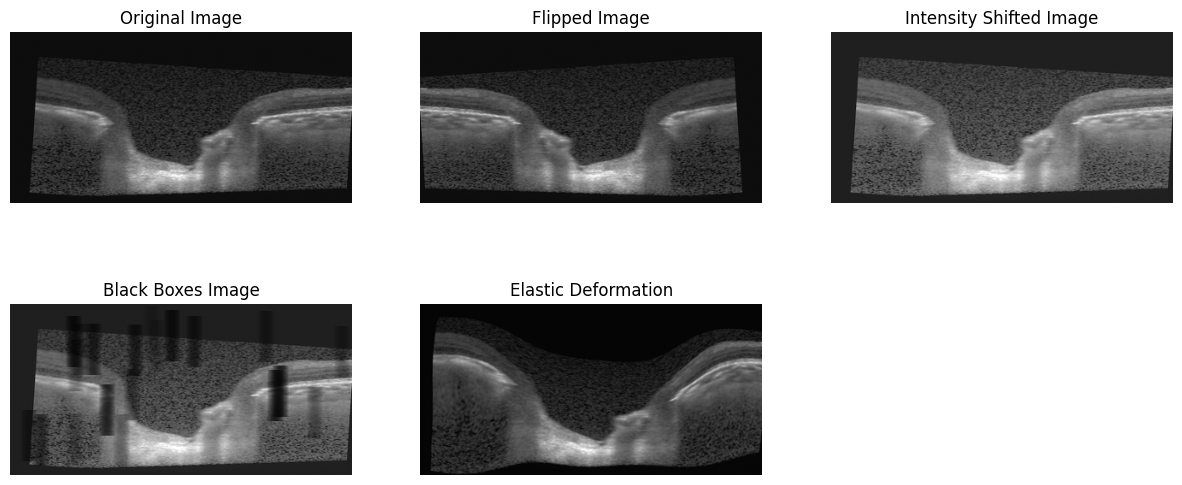

In [13]:
from scipy.ndimage import map_coordinates
def visualize_augmentations(image, label, alpha=10, alpha2=15, sigma=50):
  shape = image.shape[:2]
  x_mesh, y_mesh = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))

  # Original Image
  plt.figure(figsize=(15, 10))
  plt.subplot(3, 3, 1)
  plt.imshow(image[:, :, 0], cmap='gray')
  plt.axis('off')  # Remove axes
  plt.title("Original Image")

  # Flip
  flipped_image = image[:, ::-1, :]
  plt.subplot(3, 3, 2)
  plt.imshow(flipped_image[:, :, 0], cmap='gray')
  plt.axis('off')  # Remove axes
  plt.title("Flipped Image")

  # Intensity Nonlinear Shift
  p = np.random.uniform(low=0.6, high=1.4)
  shifted_image = image.copy()
  shifted_image[:, :, 0] = shifted_image[:, :, 0]**p
  a = np.random.uniform(low=0, high=0.1)
  b = np.random.uniform(low=0, high=0.1)
  shifted_image[:, :, 0] = -a + (1 + a + b) * shifted_image[:, :, 0]
  shifted_image = np.clip(shifted_image, 0., 1.)
  plt.subplot(3, 3, 3)
  plt.imshow(shifted_image[:, :, 0], cmap='gray')
  plt.axis('off')  # Remove axes
  plt.title("Intensity Shifted Image")

  # Black Boxes
  black_boxes_image = shifted_image.copy()
  black_dx = 60
  black_dy = 20
  dark_mask = np.zeros((black_dx, black_dy))
  for k in range(black_dy):
      dark_mask[:, k] = (np.abs(k - black_dy // 2) / (black_dy / 2.))**2
  for k in range(20):
      black_x, black_y = randint(0, shape[0] - black_dx), randint(0, shape[1] - black_dy)
      intensity_dark = np.random.uniform(low=0.2, high=0.8)
      window_to_darken = black_boxes_image[black_x:(black_x + black_dx), black_y:(black_y + black_dy), 0]
      black_boxes_image[black_x:(black_x + black_dx), black_y:(black_y + black_dy), 0] = window_to_darken * (
                  intensity_dark + (1. - intensity_dark) * dark_mask)
  plt.subplot(3, 3, 4)
  plt.imshow(black_boxes_image[:, :, 0], cmap='gray')
  plt.axis('off')  # Remove axes
  plt.title("Black Boxes Image")

   # Elastic Deformation
  
  g_1d = signal.windows.gaussian(300, sigma)
  kernel_deform = np.outer(g_1d, g_1d)

  dx = signal.fftconvolve(np.random.rand(*shape) * 2 - 1, kernel_deform, mode='same')
  dy = signal.fftconvolve(np.random.rand(*shape) * 2 - 1, kernel_deform, mode='same')

  # Normalize displacement fields
  dx = alpha * (dx - np.mean(dx)) / np.std(dx)
  dy = alpha2 * (dy - np.mean(dy)) / np.std(dy)

  # Compute new indices
  indices_x = np.clip(x_mesh + dx, 0, shape[1] - 1).astype(np.float32)
  indices_y = np.clip(y_mesh + dy, 0, shape[0] - 1).astype(np.float32)

  # Apply deformation using interpolation
  deformed_image = np.zeros_like(image)
  for i in range(image.shape[2]):  # Loop over channels
      deformed_image[:, :, i] = map_coordinates(image[:, :, i], [indices_y, indices_x], order=1, mode='reflect')

  # Display the deformed image
  plt.subplot(3, 3, 5)
  plt.imshow(deformed_image[:, :, 0], cmap='gray')
  plt.axis('off')  # Remove axes
  plt.title("Elastic Deformation")

sample_index = 0

# Get the sample image and label
sample_image = train_imgs[sample_index]
sample_labels = train_labels[sample_index]

# Ensure the image is 3D (H, W, 1)
if sample_image.ndim == 2:
    sample_image = np.expand_dims(sample_image, axis=-1)

#print("Processed Sample Image Shape:", sample_image.shape)  # Debugging step

# Call the function to visualize augmentations
visualize_augmentations(sample_image, sample_labels)

# Show the plots
plt.show()
# # @interact(x=(0,len(OCT_img)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)
# # def h(x=0): #Starting number of the slider
# #     visualize_augmentations(OCT_img, train_labels)

# #    # # f = plt.figure(figsize=(12,6))

# #    # # f.add_subplot(1,3, 1)
# #    #  plt.imshow(OCT_img[x,:,:,0], cmap='gray')
# #    #  plt.axis('off')  # Remove axes

In [14]:
# Generate augmentation
#nb_classes = 8
batch_sz = 4
training_gen = DataGen(train_images, train_labels, batch_sz, mode=True)
val_gen = DataGen(val_images, val_labels, batch_sz, mode=False)


im,seg = next(training_gen)
print("Dim(image)=",np.shape(im))
print("Dim(Label)=",np.shape(seg))

Dim(image)= (4, 200, 400, 1)
Dim(Label)= (4, 200, 400, 8)


In [15]:
@interact(x=(0,len(im)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)
def h(x=0): #Starting number of the slider

    f = plt.figure(figsize=(12,6))

    f.add_subplot(1,3, 1)
    plt.imshow(im[x,:,:,0], cmap='gray')
    plt.axis('off')  # Remove axes

    f.add_subplot(1,3, 2)
    color_label= process_label(np.argmax(seg[x], axis=2)+1)
    plt.imshow(color_label)
    plt.axis('off')  # Remove axes

    f.add_subplot(1,3, 3)
    plt.imshow(im[x,:,:,0], cmap="gray")
    plt.imshow(color_label,alpha=0.2)
    plt.axis('off')  # Remove axes
    plt.show()

interactive(children=(IntSlider(value=0, description='x', max=3), Output()), _dom_classes=('widget-interact',)…

 # UNet architecture

In [16]:
def unet(img_rows, img_cols, nb_classes):
    inputs = tf.keras.Input(shape=(img_rows, img_cols, 1))
    conv1 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(inputs)
    conv1 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
    conv2 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(pool1)
    conv2 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
    conv3 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(pool2)
    conv3 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)
    conv4 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(pool3)
    conv4 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
    drop4 = Dropout(0.5)(conv4)
    pool4 = MaxPooling2D(pool_size=(1, 1))(drop4)
    conv5 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(pool4)
    conv5 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv5)
    drop5 = Dropout(0.5)(conv5)
    up6 = Conv2D(64, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (1,1))(drop5))
    merge6 = concatenate([drop4,up6], axis = 3)
    conv6 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(merge6)
    conv6 = Conv2D(64, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv6)
    up7 = Conv2D(32, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv6))
    merge7 = concatenate([conv3,up7], axis = 3)
    conv7 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(merge7)
    conv7 = Conv2D(32, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv7)
    up8 = Conv2D(16, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv7))
    merge8 = concatenate([conv2,up8], axis = 3)
    conv8 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(merge8)
    conv8 = Conv2D(16, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv8)
    up9 = Conv2D(8, 2, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(UpSampling2D(size = (2,2))(conv8))
    merge9 = concatenate([conv1,up9], axis = 3)
    conv9 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(merge9)
    conv9 = Conv2D(8, 3, activation = 'elu', padding = 'same', kernel_initializer = 'he_normal')(conv9)
    conv10 = Conv2D(nb_classes, 1, activation = 'softmax')(conv9)
    model = Model(inputs = [inputs], outputs = [conv10])
    return model

### custom loss function

In [17]:
import tensorflow.keras.backend as K
# def jacc_coeff_loss_tissue(y_true, y_pred):
#     loss = 0
#     for i in range(nb_classes):
#         layer_weight = 1.0
#         if i == 1:
#             layer_weight=2.0
#         loss += layer_weight * tf.reduce_sum(tf.minimum(y_true[:,:,:,i], y_pred[:,:,:,i])) / \
#                     tf.reduce_sum(tf.maximum(y_true[:,:,:,i], y_pred[:,:,:,i]))
#     loss = (1 - loss / nb_classes)
#     return loss
def vertical_penalty_loss(y_true, y_pred, penalty_weight=0.1):
    """
    Adds a vertical penalty loss to enforce ordering of class labels.

    Parameters:
    - y_true: Ground truth labels, one-hot encoded (not used directly in loss).
    - y_pred: Predicted labels, logits, or probabilities with shape (batch, height, width, classes).
    - penalty_weight: Weight of the vertical penalty term.

    Returns:
    - Penalty loss value.
    """
    # Compute difference along the vertical axis (height axis)
    diff = y_pred[:, 1:, :, :] - y_pred[:, :-1, :, :]

    # Penalize negative differences (ordering violation)
    penalty = tf.keras.backend.relu(-diff)

    # Compute the mean penalty and scale it
    penalty_loss = penalty_weight * tf.keras.backend.mean(tf.keras.backend.sum(penalty, axis=-1))

    return penalty_loss

# def dice_loss(y_true, y_pred):
#     smooth = 1e-6  # Small constant to prevent division by zero
#     y_true_f = K.flatten(y_true)  # Flatten ground truth mask
#     y_pred_f = K.flatten(y_pred)  # Flatten predicted mask
#     intersection = K.sum(y_true_f * y_pred_f)  # Compute overlap
#     return 1 - (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
    
# Combined Loss Function
# def combined_loss(y_true, y_pred, alpha=0.5, beta=0.3, gamma=0.2):
#     cce = tf.keras.losses.CategoricalCrossentropy()(y_true, y_pred)
#     dice = dice_loss(y_true, y_pred)
#     penalty = vertical_penalty_loss(y_true, y_pred)

#     return alpha * cce + beta * dice + gamma * penalty  # Weighted sum

# def combined_loss(y_true, y_pred):
#     return dice_loss(y_true, y_pred) + vertical_penalty_loss(y_true, y_pred)

### Model checkpoints

In [18]:
img_rows=H; img_cols=W

#sgd_1=tf.keras.optimizers.legacy.SGD(lr=0.005, momentum=0.05, decay=0.01, nesterov=False)
Adam= tf.keras.optimizers.Adam(learning_rate=0.0005, beta_1=0.9, beta_2=0.999, decay=0.0, amsgrad=False)  ###............


model =  unet(img_rows,img_cols,nb_classes)

#model.compile(optimizer = Adam, loss = 'categorical_crossentropy', metrics = ['accuracy']) # ....
model.compile(optimizer= Adam, loss=lambda y_true, y_pred: 0.7*tf.keras.losses.categorical_crossentropy(y_true, y_pred) + 0.3*vertical_penalty_loss(y_true, y_pred), metrics = ['accuracy'])
#model.compile(optimizer= Adam, loss=combined_loss, metrics=['accuracy'])
#model.compile(optimizer = Adam, loss=combined_loss, metrics=['accuracy'])
#model.compile(optimizer = Adam, loss = jacc_coeff_loss_tissue, metrics = ['accuracy'])


model.summary()

/home/suraj/Suraj_env/lib/python3.10/site-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(
I0000 00:00:1755077843.695815  747319 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20833 MB memory:  -> device: 0, name: NVIDIA A10, pci bus id: 0000:17:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200, 400,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 200, 400,  │         80 │ input_layer[0][0] │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 200, 400,  │        584 │ conv2d[0][0]      │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 100, 200,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 100, 200,  │      1,168 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 100, 200,  │      2,320 │ conv2d_2[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 50, 100,   │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 50, 100,   │      4,640 │ max_pooling2d_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 50, 100,   │      9,248 │ conv2d_4[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 25, 50,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 25, 50,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 25, 50,    │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 25, 50,    │          0 │ conv2d_7[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 25, 50,    │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 25, 50,    │     36,928 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 25, 50,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 25, 50,    │          0 │ conv2d_9[0][0]  

 Total params: 321,768 (1.23 MB)

 Trainable params: 321,768 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
#model.load_weights(imgpath+'/Model_checkpoints/best_weights_'+testname+'.hdf5')

best_checkpoint = ModelCheckpoint(
    filepath='./../../../../../mnt/DATA/sda1/Suraj/New directory' + '/Model_checkpoints/best_weights_' + testname + '.weights.h5',  # Use .weights.h5
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    save_weights_only=True,
    mode='auto'
)

cur_checkpoint = ModelCheckpoint(
    filepath='./../../../../../mnt/DATA/sda1/Suraj/New directory' + '/Model_checkpoints/cur_weights_' + testname + '.weights.h5',  # Use .weights.h5
    monitor='val_loss',
    verbose=0,
    save_best_only=False,
    save_weights_only=True,
    mode='auto'
)

# Define the learning rate scheduler
lrScheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    cooldown=0,
    verbose=1,
    min_lr=1e-7
)

#model.load_weights(imgpath+'/Model_checkpoints/best_weights_'+testname+'.hdf5')


### Start training

In [20]:
epochs=1000

train_mini_batch_sz =4
val_mini_batch_sz = 2
num_train_batches, num_val_batches = 32, 32

### Epoch


In [21]:
training_gen = DataGen(train_images, train_labels,train_mini_batch_sz,mode=True) # if flag is not true, then data augmentation will happen on validation also
val_gen = DataGen(val_images, val_labels, val_mini_batch_sz,mode=True) # if flag is not true, then data augmentation will happen on validation also

steps_epoch=20 #train_images.shape[0] // train_mini_batch_sz
val_steps=20 #val_images.shape[0] // val_mini_batch_sz

fit_history = model.fit(
    x=training_gen,  # Generator for training data
    steps_per_epoch=steps_epoch,
    epochs=epochs,
    validation_data=val_gen,  # Generator for validation data
    validation_steps=val_steps,
    verbose=1,
    callbacks=[best_checkpoint, cur_checkpoint]
)


Epoch 1/1000


I0000 00:00:1755077848.418127  747653 service.cc:148] XLA service 0x7f4a28023620 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1755077848.418186  747653 service.cc:156]   StreamExecutor device (0): NVIDIA A10, Compute Capability 8.6
2025-08-13 09:37:28.589557: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1755077849.051390  747653 cuda_dnn.cc:529] Loaded cuDNN version 90300


 3/20 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.1895 - loss: 1.4768 

I0000 00:00:1755077855.648411  747653 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5115 - loss: 1.0880
Epoch 1: val_loss improved from None to 1.05062, saving model to ./../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/best_weights_unet_cce_pf_weight_1.weights.h5
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 219ms/step - accuracy: 0.6583 - loss: 0.8913 - val_accuracy: 0.5850 - val_loss: 1.0506
Epoch 2/1000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.7363 - loss: 0.6754
Epoch 2: val_loss improved from 1.05062 to 0.87061, saving model to ./../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/best_weights_unet_cce_pf_weight_1.weights.h5
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.7436 - loss: 0.6738 - val_accuracy: 0.6099 - val_loss: 0.8706
Epoch 3/1000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.7543 - loss: 0.5937
Epoch 3: val_loss improved from 0.87061 to 0.84143, saving model to ./../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/best_weights_unet_c

### Print epoch history

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


(0.0, 1.0)

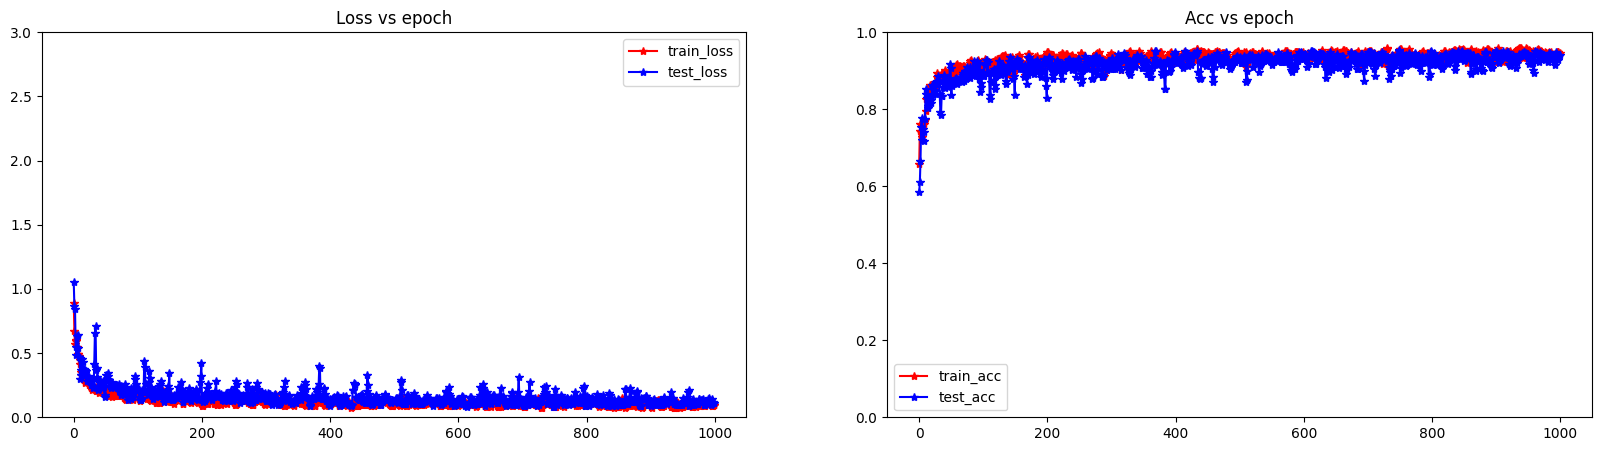

In [22]:
print(fit_history.history.keys())
plt.rcParams['figure.figsize'] = (20,5)

plt.subplot(1,2,1)
plt.title("Loss vs epoch")
plt.plot(fit_history.history["loss"], "r-*", label='train_loss')
plt.plot(fit_history.history["val_loss"], "b-*", label='test_loss')
plt.legend()
plt.ylim(0,3)

plt.subplot(1,2,2)
plt.title("Acc vs epoch")
plt.plot(fit_history.history["accuracy"], "r-*", label='train_acc')
plt.plot(fit_history.history["val_accuracy"], "b-*", label='test_acc')
plt.legend()
plt.ylim(0,1)

### Save model

In [23]:
model.save('./../../../../../mnt/DATA/sda1/Suraj/New directory'+'/Model_checkpoints/'+testname+'.h5') # Saving whole model (architecture + weights + optimizer state)
# del model  # deletes the existing model
print('FINISHED!!!!!!!')


FINISHED!!!!!!!


### Create a new model and load the best weight for testing

In [24]:
# model2 = load_model('./Model_checkpoints/'+testname+'.h5')
model.load_weights('./../../../../../mnt/DATA/sda1/Suraj/New directory'+'/Model_checkpoints/best_weights_'+testname+'.weights.h5')

print('model loaded successfully')

model loaded successfully


### Obtain Predictions

In [25]:
print(np.shape(test_images), np.shape(test_labels))

(100, 200, 400, 1) (100, 200, 400, 8)


In [26]:
#gc.collect()
#tf.keras.backend.clear_session()
test_preds = model.predict(test_images) #obtain predictions for glaucoma

print(np.shape(test_preds))
print('Predictions obtained ....')

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 326ms/step
(100, 200, 400, 8)
Predictions obtained ....


### Visualize the predictions

In [27]:
def DiceCoeff(y_true, y_pred):
    dice = np.zeros(nb_classes)
    for i in range(nb_classes):
        y_pred111 = np.round(y_pred[:,:,i])
        ttt = np.sum(np.minimum(y_true[:,:,i], y_pred111)) / \
                        (np.sum(y_true[:,:,i])+np.sum(y_pred111))
        dice[i] = 2*ttt
    return np.round((np.sum(dice)/nb_classes),2)
#combined_loss(y_true, y_pred)

0.8682000000000001 0.034187132082115344
Median: 0.8800
Lower Quartile (Q1): 0.8500
Upper Quartile (Q3): 0.8900
Lower Whisker: 0.7900
Upper Whisker: 0.9200


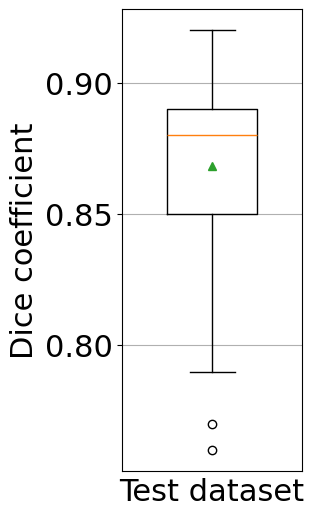

In [28]:
img_data = np.copy(test_images)
label_data = np.copy(test_labels)
label_data2 = np.copy(test_preds)

dc_all = np.zeros(len(test_images))
for i in range(len(test_images)):
    dc = DiceCoeff(label_data[i], label_data2[i])
    dc_all[i] = dc

# Compute boxplot stats manually
median = np.median(dc_all)
print(np.mean(dc_all),np.std(dc_all))
q1 = np.percentile(dc_all, 25)
q3 = np.percentile(dc_all, 75)
iqr = q3 - q1
lower_whisker = np.min(dc_all[dc_all >= q1 - 1.5 * iqr])
upper_whisker = np.max(dc_all[dc_all <= q3 + 1.5 * iqr])

print(f"Median: {median:.4f}")
print(f"Lower Quartile (Q1): {q1:.4f}")
print(f"Upper Quartile (Q3): {q3:.4f}")
print(f"Lower Whisker: {lower_whisker:.4f}")
print(f"Upper Whisker: {upper_whisker:.4f}")

# Plot
plt.rcParams.update({'font.size': 22})
f1 = plt.figure(figsize=(6,6))
plt.boxplot(dc_all, patch_artist=False, showmeans=True, showfliers=True, widths=0.5)
plt.grid(True)
plt.ylabel('Dice coefficient')
plt.xlabel('Test dataset')
plt.xticks([])
plt.subplots_adjust(right=0.5, left=0.2)
plt.show()

In [29]:
print(np.min(dc_all),np.argmin(dc_all))

0.76 68


In [30]:
@interact(x=(0,len(img_data)-1,1)) #Function responsible for creating the slider. Usage format @interact(start,end,step size)
def h(x=0): #Starting number of the slider
    f = plt.figure(figsize=(12,6))
    plt.rcParams.update({'font.size': 12})
    f.subplots_adjust(left = 0.02,right = 0.75,wspace = 0.01,hspace = 0.3)

    f.add_subplot(2, 2, 1)
    plt.imshow(img_data[x,:,:,0], cmap='gray')
    plt.axis('off')
    plt.title("Test image")

    f.add_subplot(2, 2, 2)
    color_label= process_label(np.argmax(label_data[x], axis=2)+1)
    plt.imshow(color_label)
    plt.axis('off')
    plt.title("Manual segmentation")

    f.add_subplot(2, 2, 3)
    plt.imshow(img_data[x,:,:,0], cmap='gray')
    plt.imshow(color_label,alpha=0.3)
    plt.axis('off')
    plt.title("Test image with manual segmentation")

    f.add_subplot(2, 2, 4)
    color_label2= process_label(np.argmax(label_data2[x], axis=2)+1)
    plt.imshow(color_label2)
    plt.axis('off')
    plt.title("Network prediction")


    # plt.savefig('./'+str(x) +'.png',dpi=200)

    plt.show()

interactive(children=(IntSlider(value=0, description='x', max=99), Output()), _dom_classes=('widget-interact',…